# 06 · Reconsultas a urgencias 

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / 'src' / 'config.py').exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from src import config
from src.estadistica import tabla_proporciones
from src.graficos import (
    COLORES_GRUPO,
    ETIQUETAS_CORTAS_GRUPO,
    ETIQUETAS_GRUPO,
    FONDO,
    GRISES_TECNICOS,
    TEXTO_SECUNDARIO,
    ancho_linea,
    aplicar_estilo,
    etiquetar_final,
    guardar_figura,
    marcar_umbrales,
    rotular_barras,
)
from matplotlib.patches import Patch
from src.privacidad import suprimir_pequenos, tabla_segura

aplicar_estilo()
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

G1, G2, G3, G4 = config.GRUPOS
ERROR_KW = {'elinewidth': 1, 'ecolor': TEXTO_SECUNDARIO}

In [2]:
ruta_episodios = config.DATA_INTERIM / f'episodios_urgencias_{config.UMBRAL_FUSION_MIN}min.parquet'
if not ruta_episodios.exists():
    raise FileNotFoundError('No existe el parquet de episodios: ejecuta primero notebooks/02_episodios.ipynb.')

episodios = pd.read_parquet(ruta_episodios)
episodios['hora_llegada'] = episodios['llegada'].dt.hour
los_con_tiempo = episodios['los_h'].where(episodios['grupo'].isin(list(config.GRUPOS_TIEMPOS)))
episodios['tramo_los'] = pd.cut(
    los_con_tiempo,
    bins=[0, 4, 12, 24, np.inf],
    right=False,
    labels=['menos de 4 h', '4 a 12 h', '12 a 24 h', '24 h o más'],
)
print('Episodios (filas, columnas):', episodios.shape)


def puntos_validos(tabla):
    # Para gráficos: solo se dibujan proporciones con denominador y numerador de al menos MIN_CELDA.
    return (tabla['n'] >= config.MIN_CELDA) & (tabla['n_eventos'] >= config.MIN_CELDA)

Episodios (filas, columnas): (440202, 32)


## 1. Tasas de reconsulta por grupo

Reconsulta a 72 h y a 7 días, con y sin censura, con intervalo de confianza de Wilson al 95 %. Referencia de DBeaver (sin censura, 72 h): 5,65 % en no hospitalizados y 3,27 % en hospitalizados.

In [3]:
partes = []
datos = episodios.assign(total='todos')
for ventana in config.VENTANAS_RECONSULTA:
    for censura, columna in [('con_censura', f'reconsulta_{ventana}'), ('sin_censura', f'reconsulta_{ventana}_sin_censura')]:
        for por in ['grupo', 'total']:
            tabla = tabla_proporciones(datos, [por], columna).rename_axis('grupo')
            partes.append(tabla.assign(ventana=ventana, censura=censura).set_index(['ventana', 'censura'], append=True))

tasas = pd.concat(partes).reorder_levels(['ventana', 'censura', 'grupo']).sort_index()
tabla_segura(tasas)

n  n_eventos  pct_eventos  ic_inf_eventos  ic_sup_eventos
ventana censura     grupo                                                                               
72h     con_censura 1_contacto_breve      202929      10559         5.20            5.11            5.30
                    2_no_hosp_atencion    194038      11905         6.14            6.03            6.24
                    3_hosp_con_hora_piso   36264       1048         2.89            2.72            3.07
                    4_hosp_sin_hora_piso    6292        347         5.51            4.98            6.11
                    todos                 439523      23859         5.43            5.36            5.50
        sin_censura 1_contacto_breve      203136      10561         5.20            5.10            5.30
                    2_no_hosp_atencion    194392      11911         6.13            6.02            6.23
                    3_hosp_con_hora_piso   36382       1048         2.88            2.71            3.06
                    4_hosp_sin_hora_piso    6292        347         5.51            4.98            6.11
                    todos                 440202      23867         5.42            5.36            5.49
7d      con_censura 1_contacto_breve      202678      15721         7.76            7.64            7.87
                    2_no_hosp_atencion    193786      18343         9.47            9.34            9.60
                    3_hosp_con_hora_piso   36216       2235         6.17            5.93            6.42
                    4_hosp_sin_hora_piso    6292        517         8.22            7.56            8.92
                    todos                 438972      36816         8.39            8.31            8.47
        sin_censura 1_contacto_breve      203136      15738         7.75            7.63            7.86
                    2_no_hosp_atencion    194392      18369         9.45            9.32            9.58
                    3_hosp_con_hora_piso   36382       2236         6.15            5.90            6.40
                    4_hosp_sin_hora_piso    6292        517         8.22            7.56            8.92
                    todos                 440202      36860         8.37            8.29            8.46

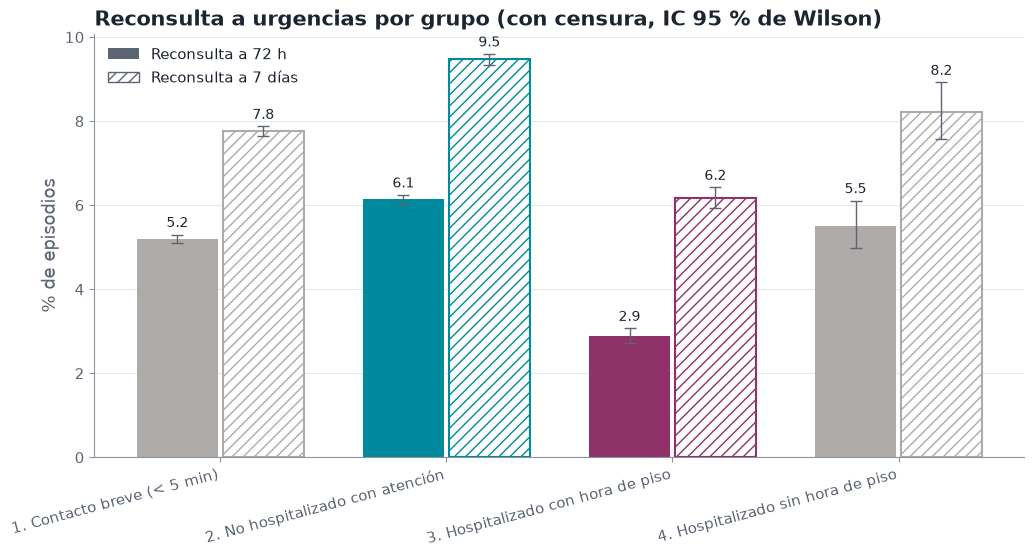

In [4]:
con_censura = tasas.xs('con_censura', level='censura')
grupos = list(config.GRUPOS)
x = np.arange(len(grupos))

# El color sigue al grupo; la ventana se distingue por el relleno: 72 h sólido y 7 días rayado.
colores = [COLORES_GRUPO[g] for g in grupos]
fig, ax = plt.subplots(figsize=(12, 5.5))
for j, ventana in enumerate(config.VENTANAS_RECONSULTA):
    tabla = con_censura.xs(ventana, level='ventana').reindex(grupos)
    valido = puntos_validos(tabla)
    pct = tabla['pct_eventos'].where(valido)
    errores = np.vstack([(pct - tabla['ic_inf_eventos']).to_numpy(), (tabla['ic_sup_eventos'] - pct).to_numpy()])
    estilo = {'color': colores} if j == 0 else {'color': FONDO, 'edgecolor': colores, 'hatch': '///', 'linewidth': 1.5}
    barras = ax.bar(x + (j - 0.5) * 0.38, pct, width=0.36, yerr=errores, capsize=4, error_kw=ERROR_KW, **estilo)
    rotular_barras(ax, barras, pct, alturas=tabla['ic_sup_eventos'].where(valido))
ax.set_xticks(x, [ETIQUETAS_GRUPO[g] for g in grupos], rotation=15, ha='right')
ax.set_ylabel('% de episodios')
ax.set_title('Reconsulta a urgencias por grupo (con censura, IC 95 % de Wilson)')
ax.legend(handles=[
    Patch(facecolor=TEXTO_SECUNDARIO, label='Reconsulta a 72 h'),
    Patch(facecolor=FONDO, edgecolor=TEXTO_SECUNDARIO, hatch='///', label='Reconsulta a 7 días'),
])
guardar_figura(fig, '06_reconsulta_por_grupo')
plt.show()

## 2. Tiempo hasta el siguiente episodio

Distribución, en bloques de 6 horas, del tiempo entre el fin del episodio y la llegada del siguiente, durante los primeros 7 días. Solo episodios observables a 7 días (no censurados). Por construcción no hay valores menores al umbral de fusión (60 min), porque esas visitas forman parte del mismo episodio.

,n_episodios
horas_hasta_siguiente_tramo,
"(0.0, 24.0]",9454
"(24.0, 48.0]",8481
"(48.0, 72.0]",5900
"(72.0, 96.0]",4061
"(96.0, 120.0]",3322
"(120.0, 144.0]",2822
"(144.0, 168.0]",2776


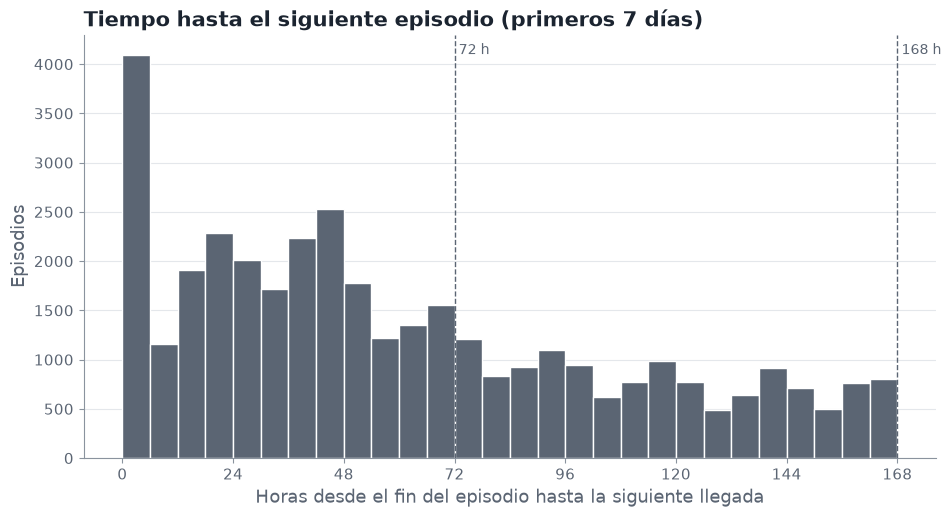

In [10]:
limite_7d_h = config.VENTANAS_RECONSULTA['7d'] / pd.Timedelta(hours=1)
observables = episodios[episodios['reconsulta_7d'].notna()]
horas = observables.loc[observables['horas_hasta_siguiente'] <= limite_7d_h, 'horas_hasta_siguiente']

por_dia = (
    pd.cut(horas, bins=np.arange(0, limite_7d_h + 1, 24), right=True)
    .value_counts().sort_index().rename('n_episodios').rename_axis('horas_hasta_siguiente_tramo').to_frame()
)
por_dia.index = por_dia.index.astype(str)
display(suprimir_pequenos(por_dia, ['n_episodios']))

bordes = np.arange(0, limite_7d_h + 1, 6)
conteos, _ = np.histogram(horas, bins=bordes)
conteos_graf = np.where(conteos >= config.MIN_CELDA, conteos, np.nan)

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.bar(bordes[:-1], conteos_graf, width=6, align='edge', color=GRISES_TECNICOS[1], edgecolor='white', linewidth=1)
marcar_umbrales(ax, [72, 168])
ax.set_xticks(range(0, int(limite_7d_h) + 1, 24))
ax.set_xlabel('Horas desde el fin del episodio hasta la siguiente llegada')
ax.set_ylabel('Episodios')
ax.set_title('Tiempo hasta el siguiente episodio (primeros 7 días)')
guardar_figura(fig, '06_tiempo_hasta_siguiente')
plt.show()

## 3. Reconsulta a 72 h por perfil del episodio índice

Con censura. Por grupo etario, sexo, hora de llegada y tramo de LOS del episodio índice (solo grupos 2 y 3, que tienen tiempos).

In [11]:
columna_72h = 'reconsulta_72h'
con_tiempos = episodios[episodios['grupo'].isin(list(config.GRUPOS_TIEMPOS))]
for variable in ['grupo_etario', 'sexo', 'hora_llegada', 'tramo_los']:
    datos = con_tiempos if variable == 'tramo_los' else episodios
    display(tabla_segura(tabla_proporciones(datos, ['grupo', variable], columna_72h)))

n n_eventos pct_eventos ic_inf_eventos ic_sup_eventos
grupo                grupo_etario                                                            
1_contacto_breve     adulto        127941      6040        4.72           4.61           4.84
                     adulto_mayor   16158       728        4.51            4.2           4.84
                     pediatria      58817      3790        6.44           6.25           6.65
                     sin_dato          13       <10   suprimido      suprimido      suprimido
2_no_hosp_atencion   adulto        119149      7505         6.3           6.16           6.44
                     adulto_mayor   25636      1204         4.7           4.44           4.96
                     pediatria      49246      3196        6.49           6.28           6.71
                     sin_dato         <10       <10   suprimido      suprimido      suprimido
3_hosp_con_hora_piso adulto         21153       628        2.97           2.75           3.21
                     adulto_mayor    7237       193        2.67           2.32           3.06
                     pediatria       7874       227        2.88           2.54           3.28
4_hosp_sin_hora_piso adulto          4067       226        5.56           4.89            6.3
                     adulto_mayor     617        20        3.24           2.11           4.95
                     pediatria       1608       101        6.28            5.2           7.57

n n_eventos pct_eventos ic_inf_eventos ic_sup_eventos
grupo                sexo                                                                       
1_contacto_breve     femenino         109487      5480        5.01           4.88           5.14
                     masculino         93408      5077        5.44           5.29           5.58
                     otro_o_sin_dato      34       <10   suprimido      suprimido      suprimido
2_no_hosp_atencion   femenino         112489      6928        6.16           6.02            6.3
                     masculino         81529      4977         6.1           5.94           6.27
                     otro_o_sin_dato      20       <10   suprimido      suprimido      suprimido
3_hosp_con_hora_piso femenino          20663       596        2.88           2.66           3.12
                     masculino         15601       452         2.9           2.65           3.17
4_hosp_sin_hora_piso femenino           3585       201        5.61            4.9           6.41
                     masculino          2707       146        5.39            4.6           6.31

n n_eventos pct_eventos ic_inf_eventos ic_sup_eventos
grupo                hora_llegada                                                          
1_contacto_breve     0             3207       290        9.04            8.1          10.08
                     1             2479       314       12.67          11.41          14.03
                     2             1965       243       12.37          10.98           13.9
                     3             1849       207        11.2           9.84          12.71
                     4             1717       185       10.77           9.39          12.33
...                                 ...       ...         ...            ...            ...
4_hosp_sin_hora_piso 19             205       <10   suprimido      suprimido      suprimido
                     20             224       <10   suprimido      suprimido      suprimido
                     21             203        20        9.85           6.47          14.73
                     22             169        17       10.06           6.38          15.52
                     23             130        13        10.0           5.94          16.36

[96 rows x 5 columns]

n  n_eventos  pct_eventos  ic_inf_eventos  ic_sup_eventos
grupo                tramo_los                                                                  
2_no_hosp_atencion   menos de 4 h  70738       4554         6.44            6.26            6.62
                     4 a 12 h      69153       4633         6.70            6.52            6.89
                     12 a 24 h     29546       1869         6.33            6.05            6.61
                     24 h o más    24601        849         3.45            3.23            3.69
3_hosp_con_hora_piso menos de 4 h   4438        117         2.64            2.20            3.15
                     4 a 12 h       7120        159         2.23            1.91            2.60
                     12 a 24 h      6574        215         3.27            2.87            3.73
                     24 h o más    18132        557         3.07            2.83            3.33

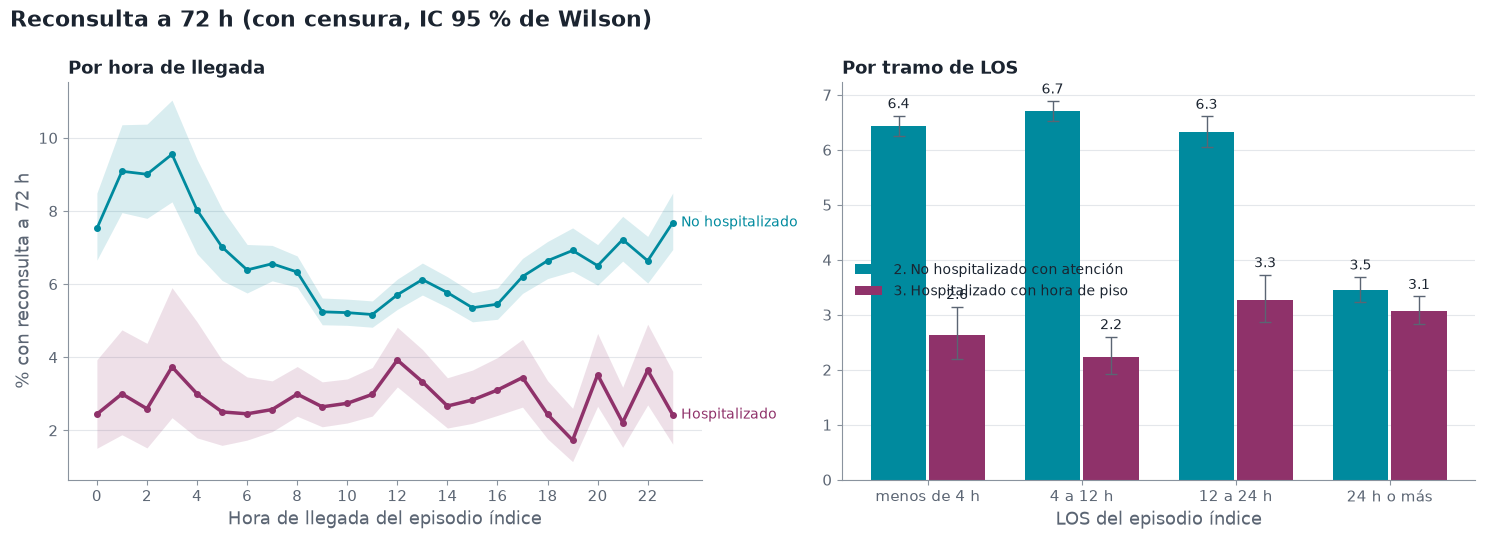

In [12]:
por_hora = tabla_proporciones(con_tiempos, ['grupo', 'hora_llegada'], columna_72h)
por_tramo = tabla_proporciones(con_tiempos, ['grupo', 'tramo_los'], columna_72h)

fig, ejes = plt.subplots(1, 2, figsize=(15, 5.5))
for grupo in config.GRUPOS_TIEMPOS:
    tabla = por_hora.xs(grupo, level='grupo')
    valido = puntos_validos(tabla)
    pct = tabla['pct_eventos'].where(valido)
    ejes[0].plot(tabla.index, pct, marker='o', markersize=4, color=COLORES_GRUPO[grupo],
                 linewidth=ancho_linea(grupo))
    ejes[0].fill_between(tabla.index, tabla['ic_inf_eventos'].where(valido), tabla['ic_sup_eventos'].where(valido),
                         color=COLORES_GRUPO[grupo], alpha=0.15, linewidth=0)
    etiquetar_final(ejes[0], tabla.index, pct, ETIQUETAS_CORTAS_GRUPO[grupo], color=COLORES_GRUPO[grupo])
ejes[0].set_xticks(range(0, 24, 2))
ejes[0].set_xlabel('Hora de llegada del episodio índice')
ejes[0].set_ylabel('% con reconsulta a 72 h')
ejes[0].set_title('Por hora de llegada', fontsize=13)

tramos = list(episodios['tramo_los'].cat.categories)
x = np.arange(len(tramos))
for j, grupo in enumerate(config.GRUPOS_TIEMPOS):
    tabla = por_tramo.xs(grupo, level='grupo').reindex(tramos)
    valido = puntos_validos(tabla)
    pct = tabla['pct_eventos'].where(valido)
    errores = np.vstack([(pct - tabla['ic_inf_eventos']).to_numpy(), (tabla['ic_sup_eventos'] - pct).to_numpy()])
    barras = ejes[1].bar(x + (j - 0.5) * 0.38, pct, width=0.36, color=COLORES_GRUPO[grupo],
                         label=ETIQUETAS_GRUPO[grupo], yerr=errores, capsize=4, error_kw=ERROR_KW)
    rotular_barras(ejes[1], barras, pct, alturas=tabla['ic_sup_eventos'].where(valido))
ejes[1].legend(fontsize=10)
ejes[1].set_xticks(x, tramos)
ejes[1].set_xlabel('LOS del episodio índice')
ejes[1].set_title('Por tramo de LOS', fontsize=13)

fig.suptitle('Reconsulta a 72 h (con censura, IC 95 % de Wilson)', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
guardar_figura(fig, '06_reconsulta_hora_tramo_los')
plt.show()

## 4. Usuarios frecuentes

Número de episodios por paciente en cada año (hasta `FECHA_CORTE_TENDENCIAS`; 2026 es un año parcial). Solo se muestra la tabla de frecuencias agregada: pacientes y episodios por categoría (1, 2, 3, 4–5, 6–9, 10 o más).

In [13]:
hasta_corte = episodios[episodios['llegada'] <= config.FECHA_CORTE_TENDENCIAS]
por_paciente_anio = hasta_corte.groupby([hasta_corte['person_id'], hasta_corte['llegada'].dt.year.rename('anio')]).size()
conteo_anual = pd.DataFrame({
    'anio': por_paciente_anio.index.get_level_values('anio'),
    'categoria': pd.cut(
        por_paciente_anio.to_numpy(), bins=[0, 1, 2, 3, 5, 9, np.inf], labels=['1', '2', '3', '4-5', '6-9', '10+']
    ),
    'episodios': por_paciente_anio.to_numpy(),
})
del por_paciente_anio  # se descarta el nivel con identificadores

pacientes = conteo_anual.groupby(['categoria', 'anio'], observed=False).size().unstack('anio', fill_value=0)
episodios_cat = conteo_anual.groupby(['categoria', 'anio'], observed=False)['episodios'].sum().unstack('anio', fill_value=0)
frecuentes = pd.concat(
    [
        pacientes.add_prefix('n_pacientes_'),
        (100 * pacientes / pacientes.sum()).add_prefix('pct_pacientes_'),
        episodios_cat.add_prefix('n_episodios_'),
        (100 * episodios_cat / episodios_cat.sum()).add_prefix('pct_episodios_'),
    ],
    axis=1,
).rename_axis('episodios_por_paciente_anio')
frecuentes.columns.name = None
tabla_segura(frecuentes, decimales=1)

,n_pacientes_2023,n_pacientes_2024,n_pacientes_2025,n_pacientes_2026,pct_pacientes_2023,pct_pacientes_2024,pct_pacientes_2025,pct_pacientes_2026,n_episodios_2023,n_episodios_2024,n_episodios_2025,n_episodios_2026,pct_episodios_2023,pct_episodios_2024,pct_episodios_2025,pct_episodios_2026
episodios_por_paciente_anio,,,,,,,,,,,,,,,,
1,65183,58521,58813,30126,69.6,70.5,71.6,81.5,65183,58521,58813,30126,45.7,46.7,48.0,64.1
2,17709,15337,14533,4939,18.9,18.5,17.7,13.4,35418,30674,29066,9878,24.8,24.5,23.7,21.0
3,6107,5144,4927,1230,6.5,6.2,6.0,3.3,18321,15432,14781,3690,12.8,12.3,12.1,7.9
4-5,3495,2989,2851,552,3.7,3.6,3.5,1.5,15036,12824,12258,2378,10.5,10.2,10.0,5.1
6-9,973,845,877,100,1.0,1.0,1.1,0.3,6571,5765,5916,658,4.6,4.6,4.8,1.4
10+,170,163,129,19,0.2,0.2,0.2,0.1,2191,2180,1680,240,1.5,1.7,1.4,0.5


## 5. Resumen para el dashboard

Tabla larga de reconsulta (72 h y 7 días, con y sin censura) por grupo y dimensión (total, grupo etario, sexo, hora de llegada y tramo de LOS). Agregada y con supresión; se exporta a `data/processed/resumen_reconsultas.csv`.

In [14]:
dimensiones = ['total', 'grupo_etario', 'sexo', 'hora_llegada', 'tramo_los']
partes = []
for ventana in config.VENTANAS_RECONSULTA:
    for censura, columna in [('con_censura', f'reconsulta_{ventana}'), ('sin_censura', f'reconsulta_{ventana}_sin_censura')]:
        for dimension in dimensiones:
            datos = con_tiempos if dimension == 'tramo_los' else episodios
            if dimension == 'total':
                categoria = pd.Series('total', index=datos.index)
            else:
                categoria = datos[dimension].astype(str).where(datos[dimension].notna())
            tabla = tabla_proporciones(datos.assign(categoria=categoria), ['grupo', 'categoria'], columna)
            partes.append(
                tabla.assign(ventana=ventana, censura=censura, dimension=dimension)
                .set_index(['ventana', 'censura', 'dimension'], append=True)
            )

resumen_reconsultas = pd.concat(partes).reorder_levels(['ventana', 'censura', 'dimension', 'grupo', 'categoria'])
resumen_reconsultas_seguro = tabla_segura(resumen_reconsultas, decimales=3)

config.DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
resumen_reconsultas_seguro.reset_index().to_csv(config.DATA_PROCESSED / 'resumen_reconsultas.csv', index=False)
print('Filas exportadas a data/processed/resumen_reconsultas.csv:', len(resumen_reconsultas_seguro))

Filas exportadas a data/processed/resumen_reconsultas.csv: 528
